# Практическая работа 7 Ансамблевое обучение
Албахтин И.В., ИНБО-12-23. Регрессия среднего времени прослушивания подкастов. На одних признаках сравниваются BaggingRegressor и градиентный HistGradientBoostingRegressor; добавлены тренировочное среднее и одиночное дерево. Notebook совместим с Colab: предварительно загрузите podcast_dataset.csv в каталог с notebook либо в data/.

In [1]:
from pathlib import Path
from time import perf_counter
from statistics import median
import hashlib,json,platform,os,copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn,joblib
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor,HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
ROOT=Path.cwd();OUT=ROOT/'results/pr7';OUT.mkdir(parents=True,exist_ok=True)
MODELS=ROOT/'models/pr7';MODELS.mkdir(parents=True,exist_ok=True)
data_path=ROOT/'data/podcast_dataset.csv'
if not data_path.exists():data_path=ROOT/'podcast_dataset.csv'
if not data_path.exists():raise FileNotFoundError('Загрузите предоставленный podcast_dataset.csv в data/ или в рабочий каталог Colab')
raw=pd.read_csv(data_path);assert raw.shape==(52500,11)
target='Listening_Time_minutes';duplicates=int(raw.duplicated().sum())
data=raw.drop_duplicates().copy();missing_target=int(data[target].isna().sum())
data=data.dropna(subset=[target]).reset_index(drop=True)
assert (data[target]>=0).all()
numeric=['Episode_Length_minutes','Host_Popularity_percentage','Guest_Popularity_percentage','Number_of_Ads']
categorical=['Genre','Publication_Day','Publication_Time','Episode_Sentiment']
predictors=numeric+categorical
quality={'raw_rows':len(raw),'exact_duplicates_removed':duplicates,'unlabelled_rows_removed':missing_target,'used_rows':len(data),'nulls_before':raw.isna().sum().to_dict(),'podcast_groups':int(data.Podcast_Name.nunique()),'inconsistent_episode_lengths':int(data.groupby(['Podcast_Name','Episode_Title']).Episode_Length_minutes.nunique().gt(1).sum())}
print(quality)

{'raw_rows': 52500, 'exact_duplicates_removed': 2500, 'unlabelled_rows_removed': 5132, 'used_rows': 44868, 'nulls_before': {'Podcast_Name': 0, 'Episode_Title': 0, 'Episode_Length_minutes': 5246, 'Genre': 0, 'Host_Popularity_percentage': 0, 'Publication_Day': 0, 'Publication_Time': 0, 'Guest_Popularity_percentage': 5258, 'Number_of_Ads': 0, 'Episode_Sentiment': 0, 'Listening_Time_minutes': 5395}, 'podcast_groups': 48, 'inconsistent_episode_lengths': 4790}


## 1 Разбиение по целым подкастам
Повторяющиеся Podcast_Name и Episode_Title не доказывают уникальный идентификатор эпизода: у одинаковых пар расходятся длины. Выбран более строгий сценарий переноса на новые подкасты. Podcast_Name определяет группы разбиения, но исключён из признаков вместе с Episode_Title. Целевые пропуски не заполняются; медианы признаков вычисляются только на train.

In [2]:
SEED=42
first=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED)
train_valid_i,test_i=next(first.split(data,groups=data.Podcast_Name))
train_valid=data.iloc[train_valid_i];test=data.iloc[test_i]
second=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED)
train_i,valid_i=next(second.split(train_valid,groups=train_valid.Podcast_Name))
train=train_valid.iloc[train_i];valid=train_valid.iloc[valid_i]
group_sets={name:set(frame.Podcast_Name) for name,frame in [('train',train),('valid',valid),('test',test)]}
assert not (group_sets['train']&group_sets['valid'] or group_sets['train']&group_sets['test'] or group_sets['valid']&group_sets['test'])
split={name:{'rows':len(frame),'groups':sorted(group_sets[name])} for name,frame in [('train',train),('valid',valid),('test',test)]}
print({k:{'rows':v['rows'],'groups':len(v['groups'])} for k,v in split.items()})
pd.DataFrame({'row_index':data.index,'split':np.select([data.index.isin(train.index),data.index.isin(valid.index)],['train','valid'],default='test')}).to_csv(OUT/'split.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].hist(train[target],bins=40);axes[0].set(title='Цель на train',xlabel='Минуты прослушивания');axes[1].bar(['train','valid','test'],[len(train),len(valid),len(test)]);axes[1].set(title='Размеры группового разбиения');fig.tight_layout();fig.savefig(OUT/'data_split.png',dpi=160);plt.show();plt.close(fig)
def preprocessing():
    return ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median'))]),numeric),('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical)],sparse_threshold=0)
def metrics(y,p):return {'rmse':float(np.sqrt(mean_squared_error(y,p))),'mae':float(mean_absolute_error(y,p)),'r2':float(r2_score(y,p))}
def pipeline(kind,parameters):
    if kind=='bagging':model=BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=parameters['depth'],min_samples_leaf=5),n_estimators=parameters['trees'],max_samples=.8,bootstrap=True,n_jobs=2,random_state=SEED)
    elif kind=='boosting':model=HistGradientBoostingRegressor(max_iter=parameters['iterations'],learning_rate=parameters['learning_rate'],max_leaf_nodes=parameters['leaves'],l2_regularization=1,early_stopping=False,random_state=SEED)
    elif kind=='tree':model=DecisionTreeRegressor(max_depth=12,min_samples_leaf=5,random_state=SEED)
    else:model=DummyRegressor(strategy='mean')
    return Pipeline([('prep',preprocessing()),('model',model)])

{'train': {'rows': 26377, 'groups': 28}, 'valid': {'rows': 9245, 'groups': 10}, 'test': {'rows': 9246, 'groups': 10}}


## 2 Подбор на valid и базовые решения
Одинаковое разбиение и набор признаков используются для обоих ансамблей. Бэггинг обучает независимые деревья на bootstrap-выборках, бустинг последовательно уточняет прогноз. Настройки выбираются по RMSE на valid. Test остаётся закрытым до выбора параметров.

In [3]:
grids={'bagging':[{'depth':8,'trees':50},{'depth':12,'trees':80}],
       'boosting':[{'iterations':100,'learning_rate':.05,'leaves':15},{'iterations':200,'learning_rate':.08,'leaves':31}]}
validation=[];selected={}
for kind,settings in grids.items():
    candidates=[]
    for parameters in settings:
        model=pipeline(kind,parameters);start=perf_counter();model.fit(train[predictors],train[target]);fit_s=perf_counter()-start
        row={'algorithm':kind,'parameters':parameters,'fit_s':fit_s,**metrics(valid[target],model.predict(valid[predictors]))}
        validation.append(row);candidates.append((row,model));print(row)
    row,model=min(candidates,key=lambda pair:pair[0]['rmse']);selected[kind]={'parameters':row['parameters'],'model':model,'validation':row}
for kind in ['mean','tree']:
    model=pipeline(kind,{});start=perf_counter();model.fit(train[predictors],train[target]);duration=perf_counter()-start
    row={'algorithm':kind,'parameters':{},'fit_s':duration,**metrics(valid[target],model.predict(valid[predictors]))};validation.append(row);selected[kind]={'parameters':{},'model':model,'validation':row}
pd.DataFrame([{**r,'parameters':json.dumps(r['parameters'])} for r in validation]).to_csv(OUT/'validation.csv',index=False)

{'algorithm': 'bagging', 'parameters': {'depth': 8, 'trees': 50}, 'fit_s': 2.318623700994067, 'rmse': 13.838067530298435, 'mae': 10.295330997677151, 'r2': 0.7482418433075059}


{'algorithm': 'bagging', 'parameters': {'depth': 12, 'trees': 80}, 'fit_s': 1.8630681119975634, 'rmse': 13.893762617452618, 'mae': 10.321895993466601, 'r2': 0.7462112260242775}


{'algorithm': 'boosting', 'parameters': {'iterations': 100, 'learning_rate': 0.05, 'leaves': 15}, 'fit_s': 0.23299489001510665, 'rmse': 13.764296453737877, 'mae': 10.25403539853092, 'r2': 0.7509189461710236}


{'algorithm': 'boosting', 'parameters': {'iterations': 200, 'learning_rate': 0.08, 'leaves': 31}, 'fit_s': 0.4037025620054919, 'rmse': 13.82521572366386, 'mae': 10.282056020101802, 'r2': 0.748709256068588}


## 3 Итоговый test и три повтора времени обучения
Параметры фиксируются до открытия test. Три повторных fit на той же train с фиксированным seed оценивают изменчивость времени; каждый раз включена та же предобработка. Замеры CPU относятся к текущему окружению и не выдаются за сравнение с GPU.

In [4]:
test_rows=[];predictions=pd.DataFrame({'row_index':test.index,'label':test[target].to_numpy()})
for kind,item in selected.items():
    model=item['model'];start=perf_counter();prediction=model.predict(test[predictors]);predict_s=perf_counter()-start
    predictions[kind]=prediction
    times=[]
    if kind in grids:
        for repeat in range(3):
            timed=pipeline(kind,item['parameters']);t=perf_counter();timed.fit(train[predictors],train[target]);times.append(perf_counter()-t)
    test_rows.append({'algorithm':kind,'parameters':item['parameters'],'fit_times':times,'fit_median':median(times) if times else item['validation']['fit_s'],'predict_s':predict_s,**metrics(test[target],prediction)})
print(pd.DataFrame(test_rows).to_string(index=False))
predictions.to_csv(OUT/'test_predictions.csv',index=False)
pd.DataFrame([{**r,'parameters':json.dumps(r['parameters']),'fit_times':json.dumps(r['fit_times'])} for r in test_rows]).to_csv(OUT/'test_metrics.csv',index=False)

algorithm                                               parameters                                                       fit_times  fit_median  predict_s      rmse       mae        r2
  bagging                                {'depth': 8, 'trees': 50}    [0.9542940339888446, 0.9284903299994767, 0.9077572759997565]    0.928490   0.128876 13.652089 10.170805  0.748099
 boosting {'iterations': 100, 'learning_rate': 0.05, 'leaves': 15} [0.22377925500040874, 0.22345111100003123, 0.25407348401495256]    0.223779   0.019596 13.594856 10.135548  0.750207
     mean                                                       {}                                                              []    0.012133   0.004343 27.217675 22.732763 -0.001229
     tree                                                       {}                                                              []    0.085722   0.004573 15.037416 11.169407  0.694383


## 4 Визуализация, сохранение и проверка
Сохраняются обе обученные цепочки вместе с медианами заполнения и словарём категорий. Повторное чтение моделей проверяется на неизменность прогноза. Ограничения: неизвестно происхождение части метаданных, нет временной даты публикации, поэтому временной перенос по этому файлу проверить нельзя.

Results saved /home/albakhtin/tiabd/АлбахтинИВ/ML/results/pr7


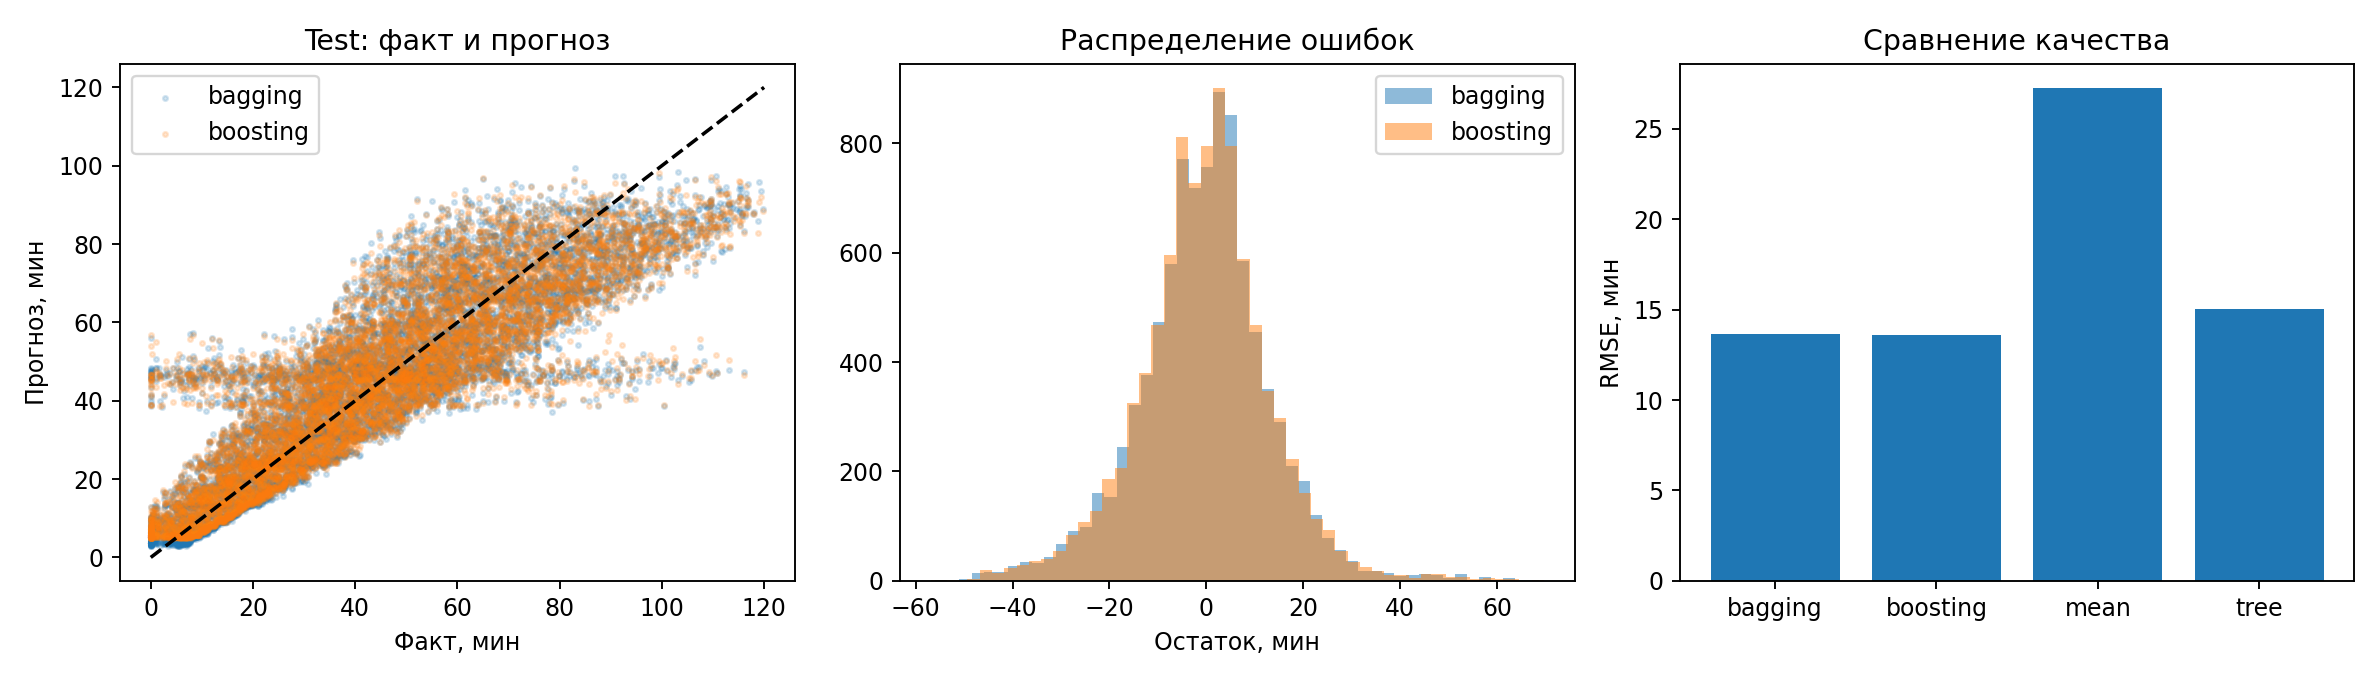

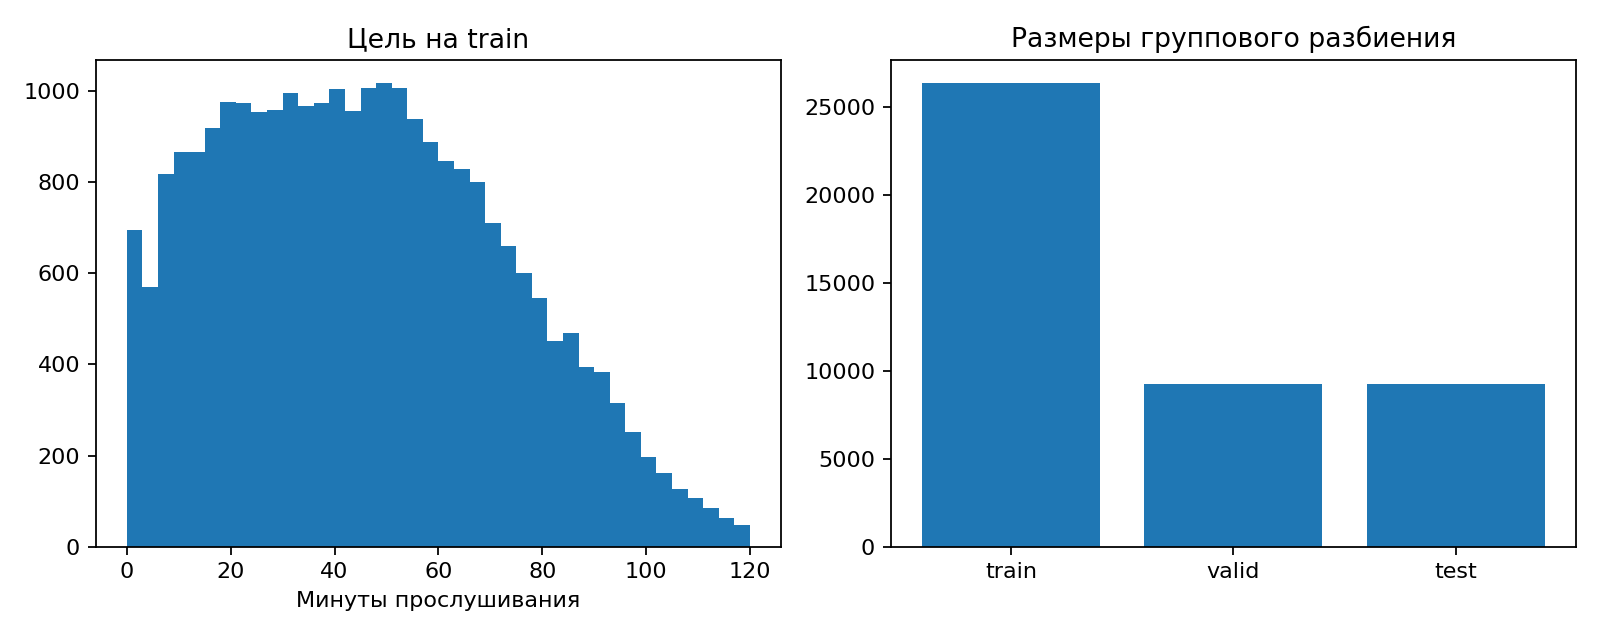

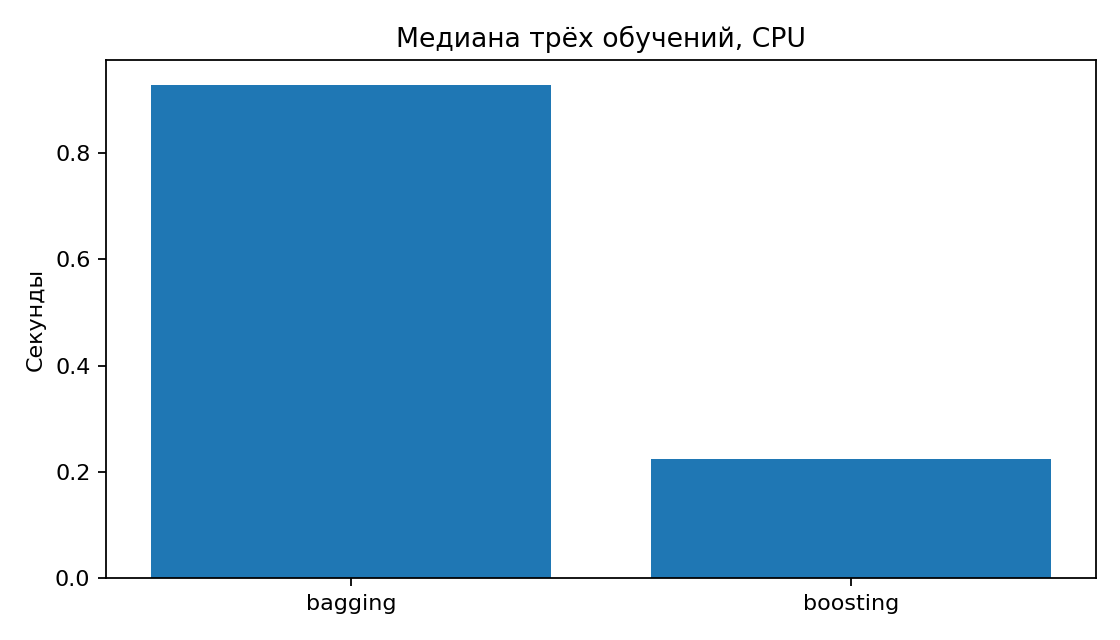

In [5]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for kind,color in [('bagging','tab:blue'),('boosting','tab:orange')]:
    axes[0].scatter(predictions.label,predictions[kind],s=4,alpha=.18,label=kind,color=color)
    axes[1].hist(predictions.label-predictions[kind],bins=50,alpha=.5,label=kind)
axes[0].plot([0,120],[0,120],'k--');axes[0].set(xlabel='Факт, мин',ylabel='Прогноз, мин',title='Test: факт и прогноз');axes[0].legend()
axes[1].set(xlabel='Остаток, мин',title='Распределение ошибок');axes[1].legend()
axes[2].bar([r['algorithm'] for r in test_rows],[r['rmse'] for r in test_rows]);axes[2].set(ylabel='RMSE, мин',title='Сравнение качества');fig.tight_layout();fig.savefig(OUT/'comparison.png',dpi=170);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4));ensemble=[r for r in test_rows if r['algorithm'] in grids];ax.bar([r['algorithm'] for r in ensemble],[r['fit_median'] for r in ensemble]);ax.set(ylabel='Секунды',title='Медиана трёх обучений, CPU');fig.tight_layout();fig.savefig(OUT/'training_time.png',dpi=160);plt.show();plt.close(fig)
for kind in grids:
    joblib.dump(selected[kind]['model'],MODELS/f'{kind}.joblib')
    loaded=joblib.load(MODELS/f'{kind}.joblib');assert np.allclose(loaded.predict(test[predictors]),predictions[kind],rtol=0,atol=1e-12)
summary={'environment':{'python':platform.python_version(),'sklearn':sklearn.__version__,'cpus':os.cpu_count(),'google_colab':bool(os.environ.get('COLAB_RELEASE_TAG'))},'source_sha256':hashlib.sha256(data_path.read_bytes()).hexdigest(),'quality':quality,'predictors':predictors,'target':target,'excluded':['Podcast_Name','Episode_Title'],'split':split,'validation':validation,'test':test_rows,'numeric_train_medians':selected['bagging']['model'].named_steps['prep'].named_transformers_['num'].named_steps['impute'].statistics_.tolist(),'roundtrip_equal':True}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8');print('Results saved',OUT)
from IPython.display import display, Image as DisplayImage
for saved_plot in sorted(OUT.glob('*.png')):
    display(DisplayImage(filename=str(saved_plot)))